<div dir="rtl">
 تحلیل جامع دیتاست کیفیت هوا (Air Quality UCI)

## معرفی دیتاست

این دیتاست حاصل داده‌های ساعتی یک دستگاه چندسنسوره‌ی شیمیایی (Multisensor Device) با ۵ سنسور اکسید فلزی است که در سطح خیابان، در یک منطقه‌ی نسبتاً آلوده‌ی یکی از شهرهای ایتالیا نصب شده بود. داده‌ها به‌صورت میانگین ساعتی، از **مارس ۲۰۰۴ تا آوریل ۲۰۰۵** (حدود یک سال) ثبت شده‌اند و شامل **۹۳۵۷ رکورد** و **۱۵ ستون** هستند.

برای هر آلاینده دو نوع مقدار ثبت شده:
- **مقدار مرجع (Ground Truth):** ستون‌های با پسوند `(GT)` — غلظت واقعی که توسط یک آنالایزر گواهی‌شده و دقیق اندازه‌گیری شده (CO, NMHC, C6H6/بنزن, NOx, NO2).
- **پاسخ خام سنسور ارزان‌قیمت:** ستون‌های `PT08.S1` تا `PT08.S5` — خروجی حسگرهای اکسید فلزی که قرار است همان آلاینده‌ها را تخمین بزنند.

علاوه بر این، سه متغیر هواشناسی هم وجود دارد: دما (`T`)، رطوبت نسبی (`RH`) و رطوبت مطلق (`AH`).

 نکته‌ی مهم: مقادیر گمشده در این دیتاست با عدد **-200** کدگذاری شده‌اند، نه NaN. اولین قدم هر تحلیلی، شناسایی و جایگزینی این مقدار است.

هدف این تحلیل، پاسخ به دو دسته سؤال است:
1. **درباره‌ی شهر:** الگوی ترافیک، فصل‌ها و آب‌وهوا چگونه روی کیفیت هوا اثر می‌گذارند؟
2. **درباره‌ی ابزار اندازه‌گیری:** آیا سنسورهای ارزان‌قیمت اکسید فلزی قابل‌اعتمادند و آیا دقتشان در طول زمان افت می‌کند (Sensor Drift)؟

منبع داده: De Vito, S. et al., *"On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario"*, Sensors and Actuators B: Chemical, 129(2), 2008.

</div>

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
df = pd.read_excel("AirQualityUCI.xlsx")

In [33]:
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


In [34]:
df.shape

(9357, 15)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   datetime64[ns]
 1   Time           9357 non-null   object        
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   int64         
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null   float64       
 11  PT08.S5(O3)    9357 non-null   float64       
 12  T              9357 non-null   float64       
 13  RH             9357 non-null   float64       
 14  AH             9357 non-null   float64       
dtypes: datetime64[ns](1),

In [36]:
df.describe()

,Date,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,2004-09-21 04:30:05.193972480,-34.207524,1048.869652,-159.090093,1.865576,894.475963,168.604200,794.872333,58.135898,1391.363266,974.951534,9.776600,39.483611,-6.837604
min,2004-03-10 00:00:00,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,2004-06-16 00:00:00,0.600000,921.000000,-200.000000,4.004958,711.000000,50.000000,637.000000,53.000000,1184.750000,699.750000,10.950000,34.050000,0.692275
50%,2004-09-21 00:00:00,1.500000,1052.500000,-200.000000,7.886653,894.500000,141.000000,794.250000,96.000000,1445.500000,942.000000,17.200000,48.550000,0.976823
75%,2004-12-28 00:00:00,2.600000,1221.250000,-200.000000,13.636091,1104.750000,284.200000,960.250000,133.000000,1662.000000,1255.250000,24.075000,61.875000,1.296223
max,2005-04-04 00:00:00,11.900000,2039.750000,1189.000000,63.741476,2214.000000,1479.000000,2682.750000,339.700000,2775.000000,2522.750000,44.600000,88.725000,2.231036
std,NaN,77.657170,329.817015,139.789093,41.380154,342.315902,257.424561,321.977031,126.931428,467.192382,456.922728,43.203438,51.215645,38.976670


## پاکسازی داده — بررسی مقادیر گمشده

حالا مقدار -200 را در تمام ستون‌ها با NaN جایگزین کرده و درصد مقادیر گمشده‌ی هر ستون را محاسبه و رسم می‌کنیم.

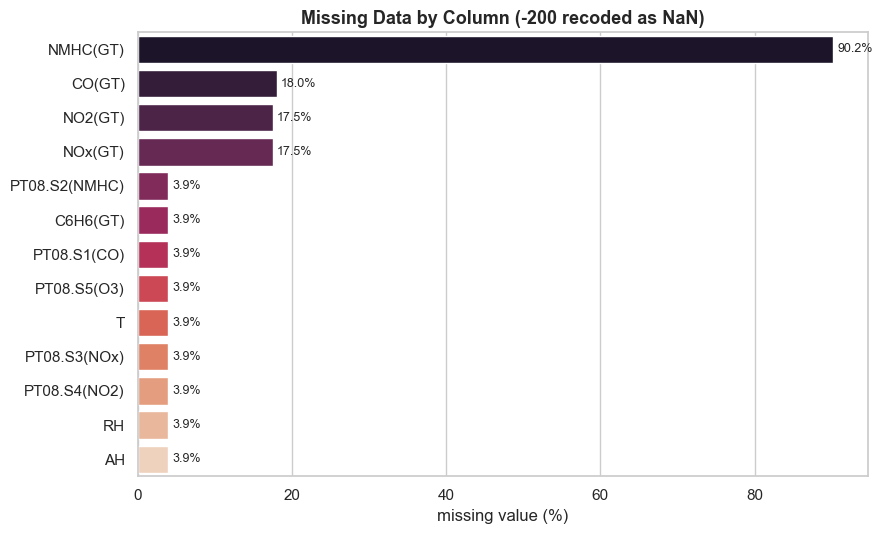

In [61]:
import numpy as np

df_missing = df.replace(-200, np.nan)

missing_pct = df_missing.isna().mean().mul(100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]  

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=missing_pct.values, y=missing_pct.index, hue=missing_pct.index,
            palette="rocket", legend=False, ax=ax)

ax.set_xlabel("missing value (%)")
ax.set_ylabel("")
ax.set_title("Missing Data by Column (-200 recoded as NaN)", fontsize=13, weight='bold')

for i, v in enumerate(missing_pct.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: ستون NMHC(GT) با فاصله‌ی زیاد بیشترین مقدار گمشده را دارد (۹۰.۲٪) — یعنی تقریباً برای اکثر ساعات سال، مقدار واقعی این آلاینده ثبت نشده و این ستون عملاً برای تحلیل آماری قابل استفاده نیست (این ضعف در خودِ مقاله‌ی اصلی دیتاست هم ذکر شده است). سه ستون مرجع دیگر (CO(GT), NO2(GT), NOx(GT)) حدود ۱۷.۵ تا ۱۸ درصد مقدار گمشده دارند که قابل مدیریت است (می‌توان سطرهای ناقص را حذف یا میان‌یابی کرد). در مقابل، ستون‌های پاسخ خام سنسورها (PT08.S...) و متغیرهای هواشناسی تنها ۳.۹٪ مقدار گمشده دارند — یعنی خودِ حسگرها بسیار پیوسته‌تر از آنالایزر مرجع کار کرده‌اند.
</div>

## بخش سوم: توزیع کلی آلاینده‌ها

قبل از بررسی روند زمانی، بهتر است شکل کلی توزیع هر آلاینده را ببینیم: آیا نرمال است یا چوله؟

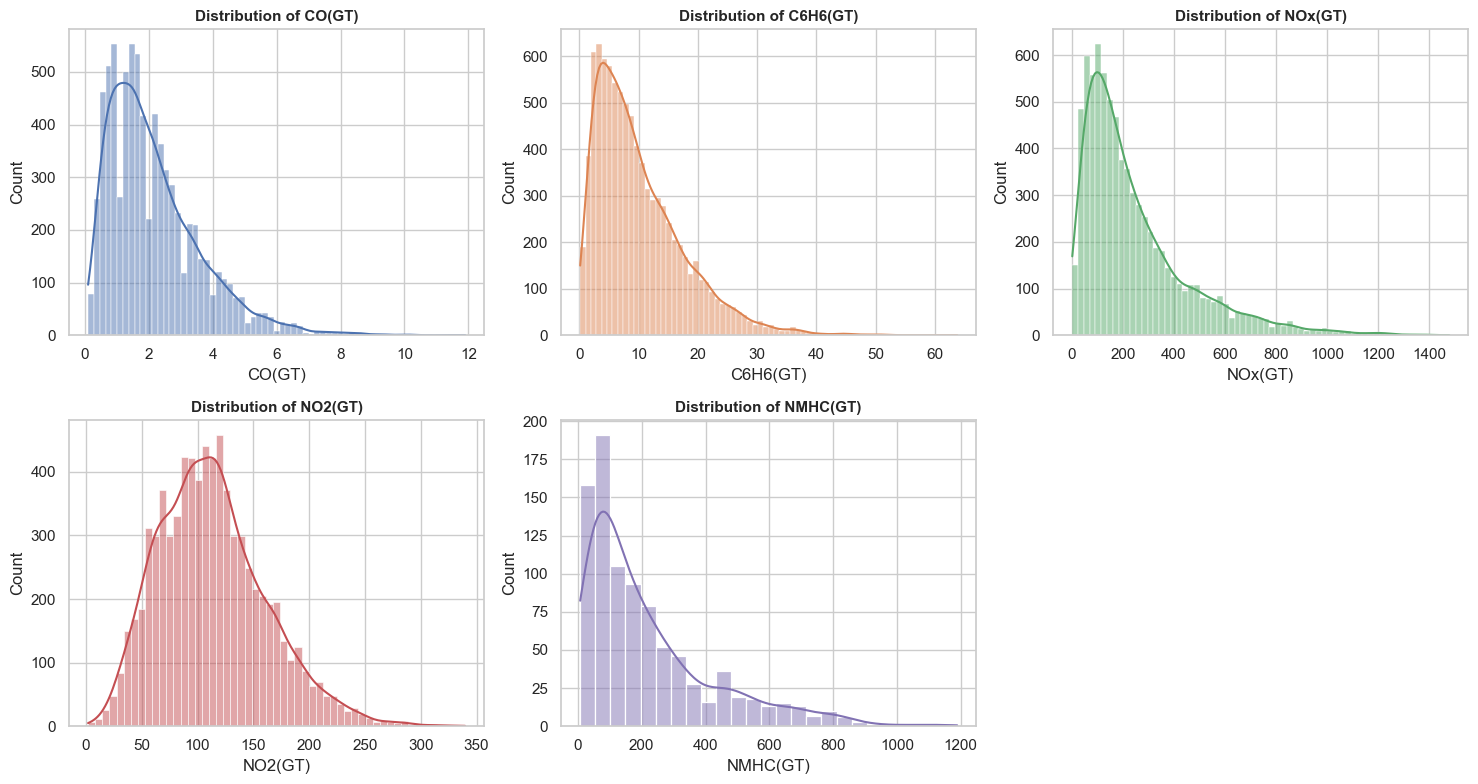

In [62]:
pollutant_cols = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'NMHC(GT)']

df_clean = df.replace(-200, np.nan)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(pollutant_cols):
    sns.histplot(df_clean[col].dropna(), kde=True, ax=axes[i], color=sns.color_palette("deep")[i])
    axes[i].set_title(f"Distribution of {col}", fontsize=11, weight='bold')
    axes[i].set_xlabel(col)

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: تمام آلاینده‌های ترافیکی (CO(GT) , C6H6(GT) , NOx(GT) , NMHC(GT)) توزیعی به‌شدت چوله به راست (Right-Skewed) دارند: اکثر مقادیر پایین و نزدیک صفرند، اما یک دنباله‌ی بلند سمت راست وجود دارد که نشان‌دهنده‌ی ساعات پرترافیک یا شرایط جوی خاص (مثل وارونگی دمایی) با غلظت‌های بسیار بالاست. این الگو کاملاً با ماهیت آلاینده‌های منتشرشده از احتراق سوخت سازگار است. در مقابل، توزیع NO2(GT) نسبتاً متقارن‌تر و نزدیک‌تر به نرمال است، که نشان می‌دهد NO2 (که هم از منابع اولیه و هم از واکنش‌های ثانویه‌ی جوی تولید می‌شود) نوسان کمتر شدیدی نسبت به بقیه دارد. این چولگی‌ها یک پیام عملی هم دارند: برای مدل‌سازی آماری این متغیرها، شاید نیاز به تبدیل لگاریتمی باشد.
</div>

In [63]:
import numpy as np

df = df.replace(-200, np.nan)
df['datetime'] = pd.to_datetime(df['Date'].astype(str)) + \
                  pd.to_timedelta(df['Time'].astype(str).str.split(':').str[0].astype(int), unit='h')
df = df.sort_values('datetime').reset_index(drop=True)

df['month'] = df['datetime'].dt.month
df['hour'] = df['datetime'].dt.hour
df['weekday'] = df['datetime'].dt.dayofweek          # Monday=0
df['weekday_name'] = df['datetime'].dt.day_name()
df['is_weekend'] = df['weekday'] >= 5

season_map = {12:'Winter',1:'Winter',2:'Winter',
              3:'Spring',4:'Spring',5:'Spring',
              6:'Summer',7:'Summer',8:'Summer',
              9:'Autumn',10:'Autumn',11:'Autumn'}
df['season'] = df['month'].map(season_map)

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.0)

## بخش چهارم: ریتم روزانه‌ی شهر — نبض ترافیک

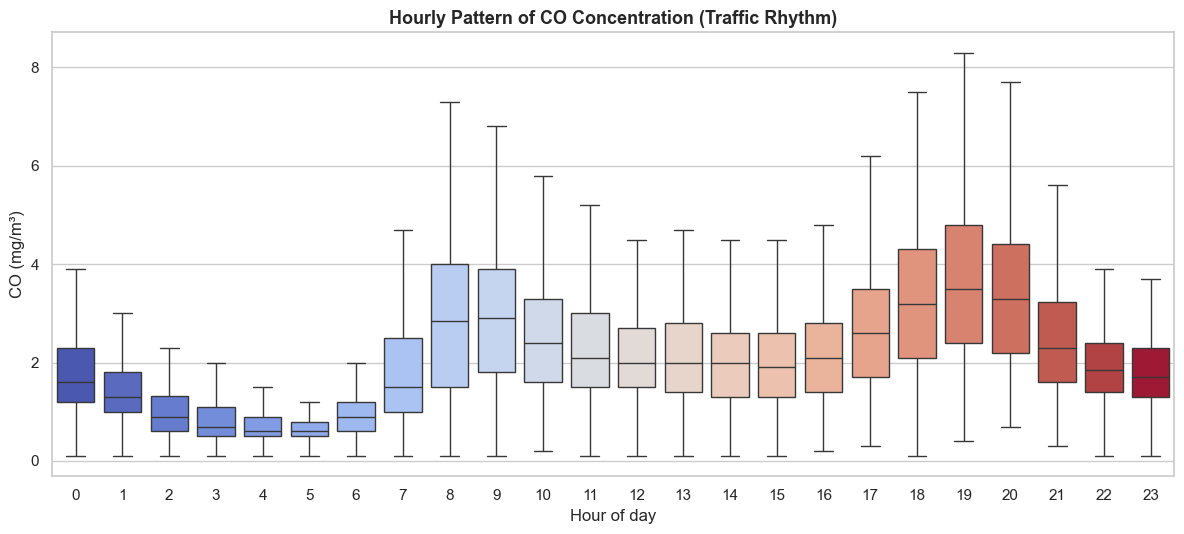

In [64]:
fig, ax = plt.subplots(figsize=(12,5.5))
sns.boxplot(data=df, x='hour', y='CO(GT)', hue='hour', palette='coolwarm', legend=False, ax=ax, showfliers=False)
ax.set_title("Hourly Pattern of CO Concentration (Traffic Rhythm)", fontsize=13, weight='bold')
ax.set_xlabel("Hour of day"); ax.set_ylabel("CO (mg/m³)")
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: الگوی کلاسیک ترافیک شهری کاملاً واضح است. دو قله‌ی مشخص در ساعت ۸ تا ۹ صبح و ۱۸ تا ۲۰ شب دیده می‌شود که دقیقاً منطبق با رفت‌وآمد صبحگاهی و عصرگاهی محل کار است، در حالی‌که کمینه‌ی غلظت در ۴ تا ۵ بامداد رخ می‌دهد. این نمودار به‌روشنی نشان می‌دهد منبع اصلی آلودگی CO در این منطقه ترافیک وسایل نقلیه است، نه یک منبع صنعتی ثابت که در تمام ساعات شبانه‌روز یکنواخت عمل کند.
</div>

### روز کاری در برابر آخر هفته

برای اطمینان از اینکه الگوی بالا واقعاً به رفتار انسانی (رفت‌وآمد کاری) مربوط است، ریتم ساعتی NOx را بین روزهای کاری و آخر هفته مقایسه می‌کنیم.

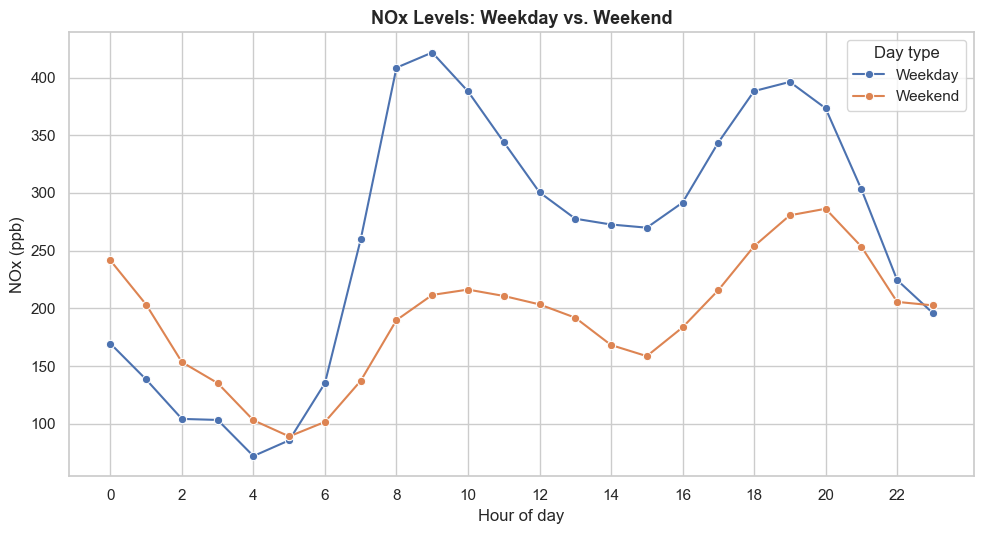

In [65]:
grp = df.groupby(['hour','is_weekend'])['NOx(GT)'].mean().reset_index()
grp['Day type'] = grp['is_weekend'].map({True:'Weekend', False:'Weekday'})

fig, ax = plt.subplots(figsize=(10,5.5))
sns.lineplot(data=grp, x='hour', y='NOx(GT)', hue='Day type', marker='o', ax=ax)
ax.set_title("NOx Levels: Weekday vs. Weekend", fontsize=13, weight='bold')
ax.set_xlabel("Hour of day"); ax.set_ylabel("NOx (ppb)")
ax.set_xticks(range(0,24,2))
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: فرضیه تأیید می‌شود. در روزهای کاری دو قله‌ی تیز و مشخص صبح و عصر دیده می‌شود که غلظت NOx را تا حدود ۴۰۰ ppb می‌رساند، درحالی‌که در آخر هفته نموداری صاف‌تر و با اوج بسیار ملایم‌تر (حدود ۲۸۰ ppb در اواخر شب) داریم. این تفاوت آشکار، ردپای مستقیم رفتار انسانی (رفتن سر کار) روی داده‌های محیطی است و ثابت می‌کند که الگوی روزانه صرفاً یک چرخه‌ی طبیعی نیست، بلکه محصول فعالیت اجتماعی است.
</div>

## بخش پنجم: الگوی فصلی آلودگی

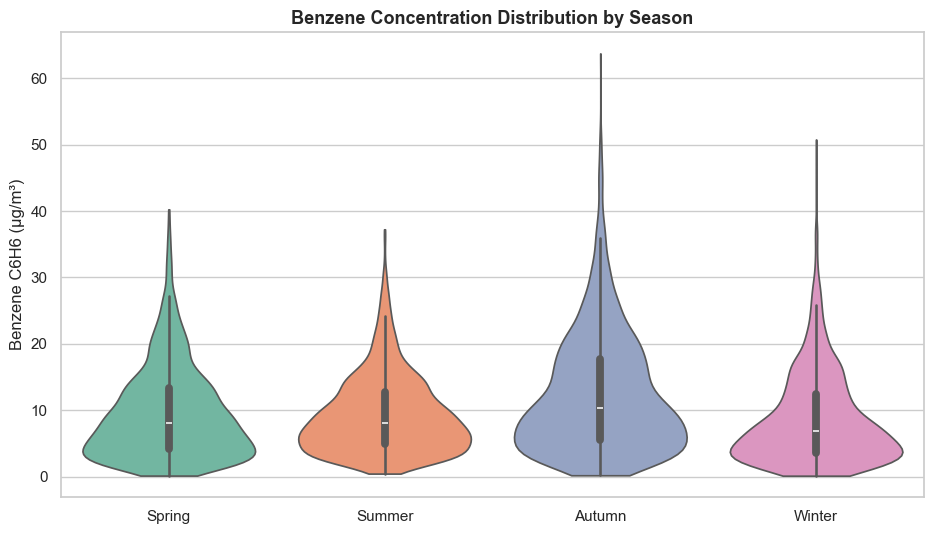

In [81]:
order = ['Spring','Summer','Autumn','Winter']

fig, ax = plt.subplots(figsize=(9.5,5.5))
sns.violinplot(data=df, x='season', y='C6H6(GT)', order=order, hue='season',
               palette='Set2', legend=False, ax=ax, cut=0)
ax.set_title("Benzene Concentration Distribution by Season", fontsize=13, weight='bold')
ax.set_xlabel(""); ax.set_ylabel("Benzene C6H6 (µg/m³)")
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: میانگین غلظت بنزن در پاییز بیشترین مقدار (نزدیک به ۱۲.۵ میکروگرم بر مترمکعب) و در زمستان کمترین میانه را نشان می‌دهد، هرچند پراکندگی (دم بالای ویولن) در پاییز و زمستان هر دو زیاد است — یعنی در این دو فصل هم روزهای خیلی پاک و هم روزهای خیلی آلوده دیده می‌شوند. این الگو نشان می‌دهد رابطه‌ی فصل و آلودگی، ساده و خطی نیست و عواملی مثل تعطیلات، جهت باد و بارش هم در کنار دما نقش دارند.
</div>

### نقشه‌ی حرارتی ساعت × روز هفته

برای دیدن هر دو الگوی روزانه و هفتگی به‌طور همزمان، یک نقشه‌ی حرارتی از میانگین CO بر اساس ساعت و روز هفته رسم می‌کنیم.

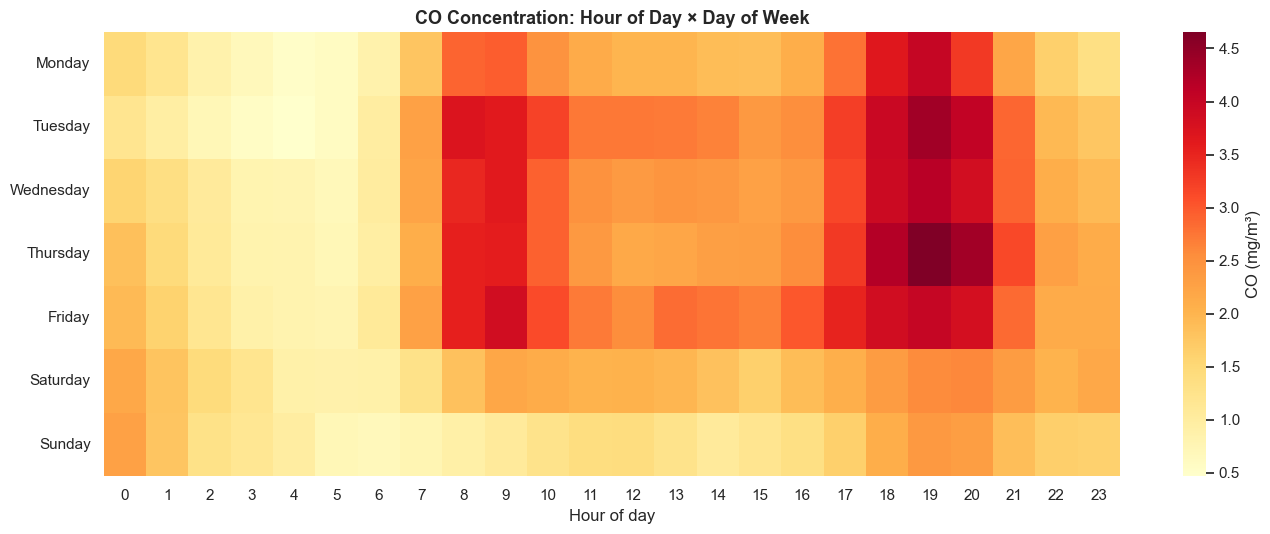

In [67]:
pivot = df.pivot_table(index='weekday_name', columns='hour', values='CO(GT)', aggfunc='mean')
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = pivot.reindex(weekday_order)

fig, ax = plt.subplots(figsize=(14,5.5))
sns.heatmap(pivot, cmap='YlOrRd', ax=ax, cbar_kws={'label':'CO (mg/m³)'})
ax.set_title("CO Concentration: Hour of Day × Day of Week", fontsize=13, weight='bold')
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: این نقشه‌ی حرارتی، خلاصه‌ی بصری بسیار گویایی از دو یافته‌ی قبلی است. نواحی تیره و پررنگ (بالاترین غلظت CO) دقیقاً در تقاطع روزهای دوشنبه تا جمعه و ساعات ۸-۹ صبح و ۱۸-۲۰ شب قرار دارند. ردیف‌های شنبه و یکشنبه به‌طور محسوسی روشن‌تر (کم‌آلوده‌تر) هستند و هیچ‌کدام از این دو روز الگوی دو-قله‌ای مشخصی ندارند. این نمودار در یک نگاه، هم ریتم روزانه و هم تفاوت هفتگی را همزمان اثبات می‌کند.
</div>

### روند فصلی نرمال‌شده در طول سال

برای مقایسه‌ی هم‌زمان چهار آلاینده با واحدهای کاملاً متفاوت (CO بر حسب mg/m³ و NOx بر حسب ppb)، ابتدا هرکدام را بین ۰ و ۱ نرمال می‌کنیم تا روی یک نمودار قابل مقایسه باشند.

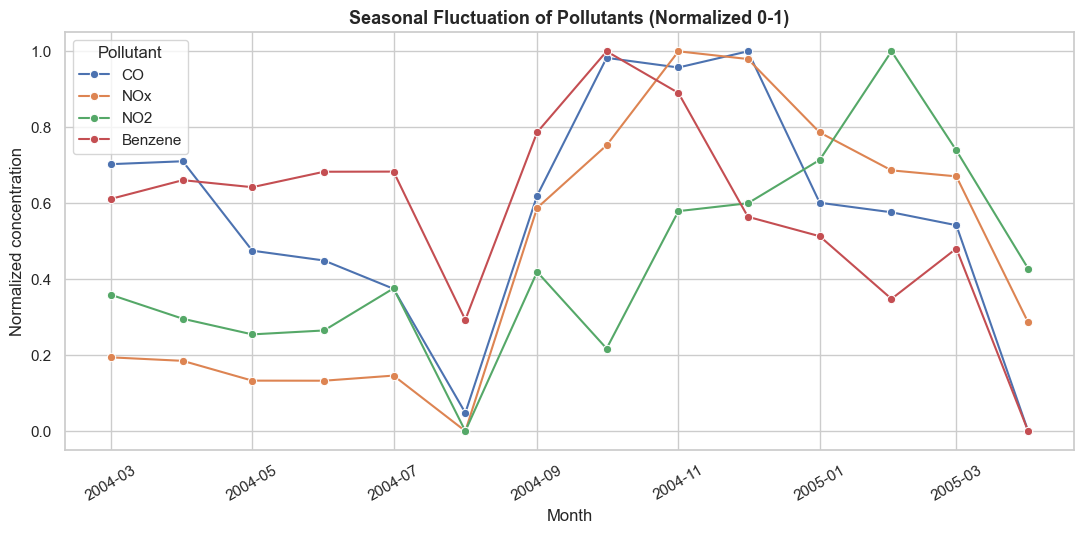

In [68]:
monthly_norm = df.groupby(df['datetime'].dt.to_period('M')).agg(
    CO=('CO(GT)','mean'), NOx=('NOx(GT)','mean'), NO2=('NO2(GT)','mean'), Benzene=('C6H6(GT)','mean')
)
monthly_norm = (monthly_norm - monthly_norm.min()) / (monthly_norm.max() - monthly_norm.min())
monthly_norm = monthly_norm.reset_index()
monthly_norm['datetime'] = monthly_norm['datetime'].dt.to_timestamp()
monthly_norm_long = monthly_norm.melt(id_vars='datetime', var_name='Pollutant', value_name='Normalized value')

fig, ax = plt.subplots(figsize=(11,5.5))
sns.lineplot(data=monthly_norm_long, x='datetime', y='Normalized value', hue='Pollutant', marker='o', ax=ax)
ax.set_title("Seasonal Fluctuation of Pollutants (Normalized 0-1)", fontsize=13, weight='bold')
ax.set_xlabel("Month"); ax.set_ylabel("Normalized concentration")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: پس از نرمال‌سازی، یک الگوی مشترک روشن می‌شود: تقریباً همه‌ی آلاینده‌ها در بازه‌ی سپتامبر تا دسامبر ۲۰۰۴ (پاییز/اوایل زمستان) به اوج خود می‌رسند و در جولای-آگوست به کمینه‌ی خود می‌رسند. این افت تابستانی به‌احتمال زیاد به‌دلیل تعطیلات تابستانی سنتی در ایتالیا و کاهش ترافیک شهری است. جالب توجه است که NO2 رفتار کمی متفاوت‌تری دارد و در فوریه‌ی ۲۰۰۵ به اوج مجزای خودش می‌رسد؛ این نشان می‌دهد NO2، برخلاف بقیه، ممکن است تحت تأثیر یک فرایند ثانویه‌ی جوی (واکنش با ازن) هم باشد، نه فقط انتشار مستقیم.
</div>

## بخش ششم: رابطه‌ی آلودگی و آب‌وهوا

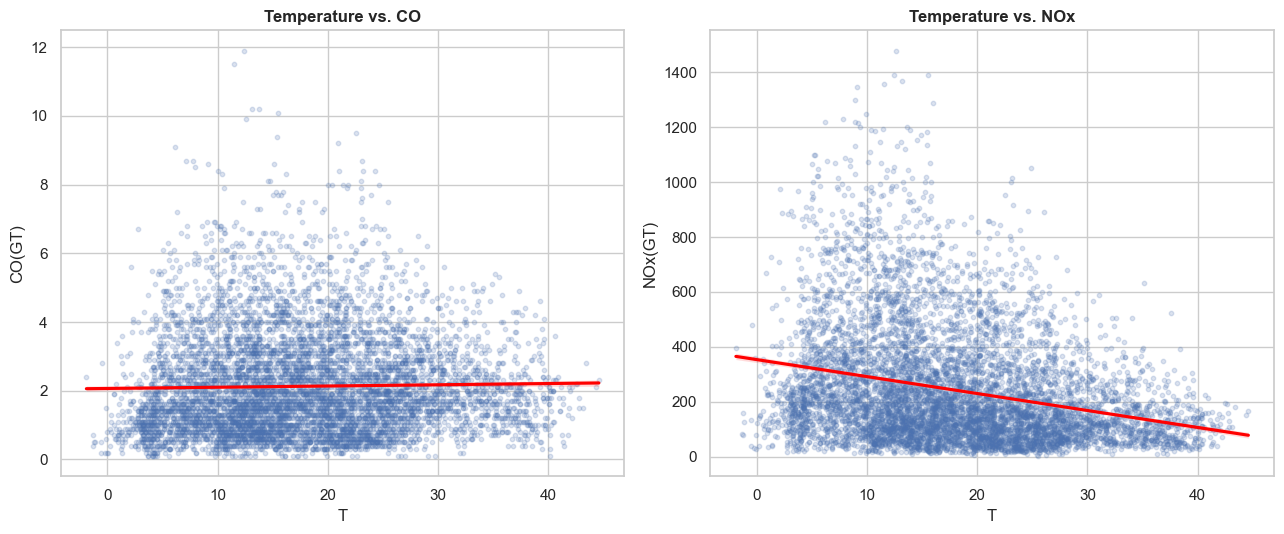

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(13,5.5))
sns.regplot(data=df, x='T', y='CO(GT)', ax=axes[0], scatter_kws={'alpha':0.2, 's':10}, line_kws={'color':'red'})
axes[0].set_title("Temperature vs. CO", fontsize=12, weight='bold')

sns.regplot(data=df, x='T', y='NOx(GT)', ax=axes[1], scatter_kws={'alpha':0.2, 's':10}, line_kws={'color':'red'})
axes[1].set_title("Temperature vs. NOx", fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: دو رفتار کاملاً متفاوت دیده می‌شود. خط رگرسیون CO تقریباً افقی و بدون شیب است — یعنی دما به‌تنهایی پیش‌بینی‌کننده‌ی خوبی برای غلظت CO نیست (چرا که CO بیشتر تابع ترافیک لحظه‌ای است تا دما). اما خط رگرسیون NOx شیب نزولی واضحی دارد؛ هرچه دما بالاتر می‌رود، غلظت NOx به‌طور میانگین کاهش می‌یابد. این با پدیده‌ی وارونگی دمایی همخوانی دارد: در هوای سرد، لایه‌ی هوای سرد نزدیک سطح زمین آلاینده‌ها را به دام می‌اندازد و مانع پراکنده‌شدنشان می‌شود.
</div>

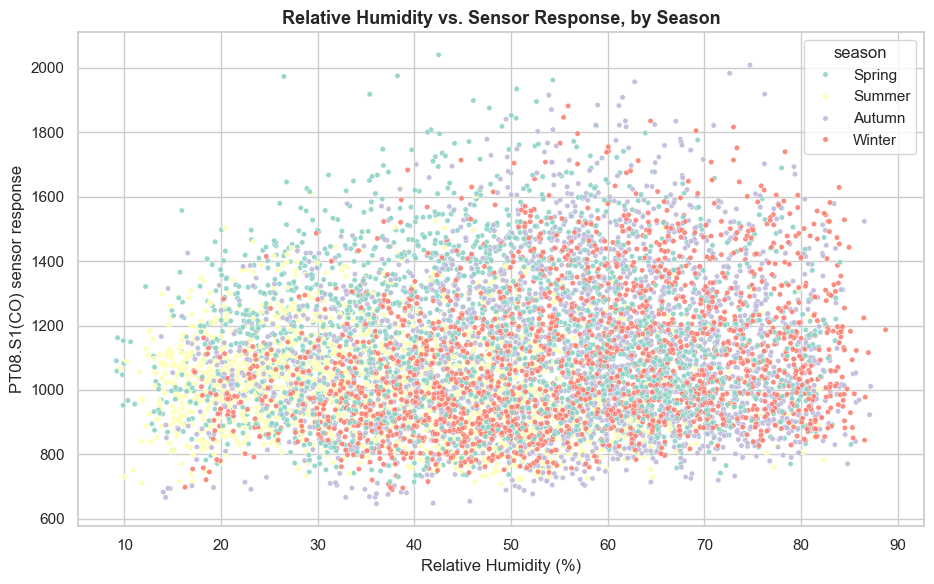

In [70]:
fig, ax = plt.subplots(figsize=(9.5,6))
sns.scatterplot(data=df, x='RH', y='PT08.S1(CO)', hue='season', hue_order=order,
                 palette='Set3', alpha=0.9, s=15, ax=ax)
ax.set_title("Relative Humidity vs. Sensor Response, by Season", fontsize=13, weight='bold')
ax.set_xlabel("Relative Humidity (%)"); ax.set_ylabel("PT08.S1(CO) sensor response")
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: پراکندگی نقاط نشان می‌دهد نقاط تابستانی (زرد) عمدتاً در سمت چپ نمودار (رطوبت پایین‌تر، حدود ۱۰ تا ۵۰٪) و در محدوده‌ی پایین‌تر پاسخ سنسور (زیر ۱۴۰۰) خوشه‌بندی شده‌اند، درحالی‌که نقاط پاییز و زمستان در رطوبت‌های بالاتر (۵۰ تا ۹۰٪) و پاسخ‌های سنسوری بالاتر پراکنده‌اند. این همبستگی غیرمستقیم قابل‌انتظار است چون فصل‌های سرد هم رطوبت بالاتری دارند و هم — همان‌طور که قبلاً دیدیم — آلودگی بیشتری. با این‌حال، همپوشانی زیاد رنگ‌ها در میانه‌ی نمودار نشان می‌دهد رطوبت به‌تنهایی متغیر تفکیک‌کننده‌ی قوی‌ای برای فصل نیست.
</div>

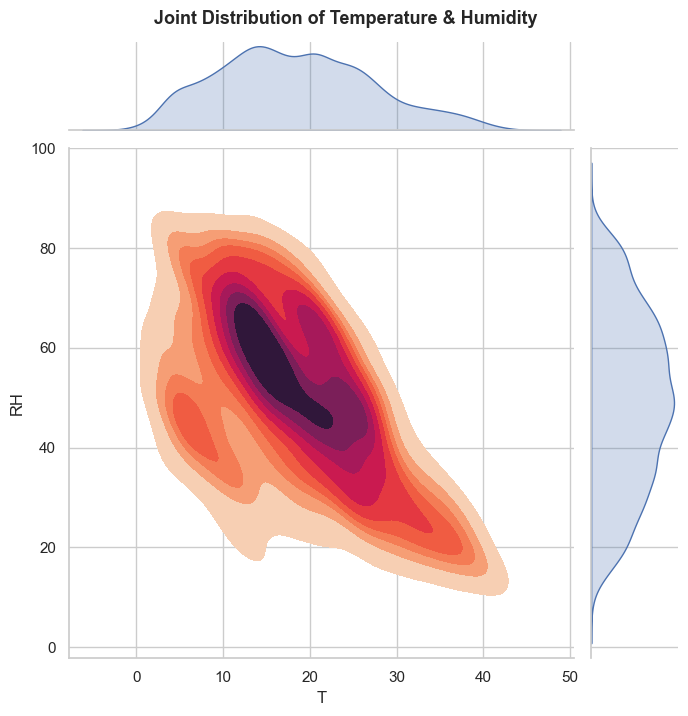

In [71]:
g = sns.jointplot(data=df, x='T', y='RH', kind='kde', fill=True, cmap='rocket_r', height=7)
g.fig.suptitle("Joint Distribution of Temperature & Humidity", fontsize=13, weight='bold', y=1.02)
plt.show()

<div dir="rtl">
تفسیر نمودار: توزیع توأم دما و رطوبت یک الگوی قطری نزولی نشان می‌دهد — چگال‌ترین ناحیه (تیره‌ترین رنگ) حوالی دمای ۱۰ تا ۲۰ درجه و رطوبت ۵۰ تا ۷۰٪ قرار دارد، و هرچه دما بالاتر می‌رود، رطوبت معمولاً پایین‌تر است. این یک رابطه‌ی فیزیکی شناخته‌شده در هواشناسی است (هوای گرم‌تر ظرفیت نگه‌داشتن رطوبت نسبی کمتری دارد) و نشان می‌دهد این دو متغیر مستقل از هم نیستند — نکته‌ای که باید در هر مدل پیش‌بینی که از هر دو به‌عنوان ویژگی استفاده می‌کند در نظر گرفته شود.
</div>

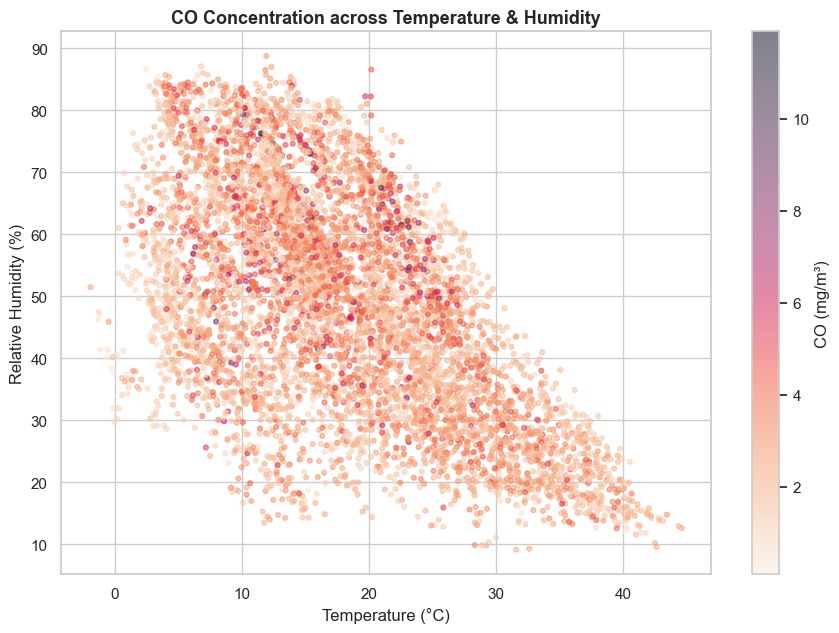

In [72]:
fig, ax = plt.subplots(figsize=(9,6.5))
sc = ax.scatter(df['T'], df['RH'], c=df['CO(GT)'], cmap='rocket_r', alpha=0.5, s=12)
plt.colorbar(sc, label='CO (mg/m³)')
ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("Relative Humidity (%)")
ax.set_title("CO Concentration across Temperature & Humidity", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: نقاط با رنگ تیره‌تر (غلظت بالای CO) عمدتاً در ناحیه‌ی دمای پایین تا متوسط (۵ تا ۲۰ درجه) و رطوبت متوسط تا بالا (۵۰ تا ۸۰٪) متمرکزند — دقیقاً همان ناحیه‌ای که در نمودار قبلی به‌عنوان پرتکرارترین ترکیب دما-رطوبت شناسایی شد. این همخوانی نشان می‌دهد بدترین آلودگی نه در سردترین روزهای زمستان (دمای زیر صفر) و نه در گرم‌ترین روزهای تابستان، بلکه در شرایط سرد و مرطوب معتدل رخ می‌دهد؛ ترکیبی که هم مانع پراکندگی آلاینده می‌شود و هم اغلب با ترافیک عادی فصل سرد همراه است.
</div>

## بخش هفتم: آیا می‌توان به سنسورهای ارزان‌قیمت اعتماد کرد؟

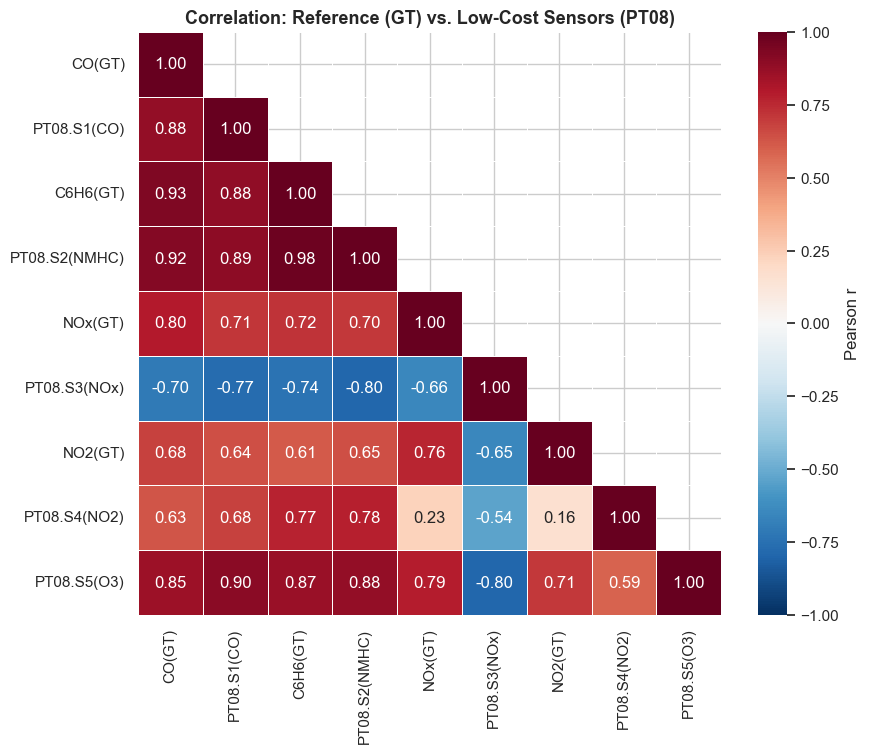

In [73]:
cols = ['CO(GT)','PT08.S1(CO)','C6H6(GT)','PT08.S2(NMHC)','NOx(GT)','PT08.S3(NOx)',
        'NO2(GT)','PT08.S4(NO2)','PT08.S5(O3)']
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(9,7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            mask=mask, square=True, linewidths=0.5, ax=ax, cbar_kws={'label':'Pearson r'})
ax.set_title("Correlation: Reference (GT) vs. Low-Cost Sensors (PT08)", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار — یک کشف مهم: بیشتر سنسورهای ارزان‌قیمت همبستگی مثبت و قوی با مقدار مرجع خود دارند؛ برای نمونه `PT08.S1(CO)` با `CO(GT)` همبستگی ۰.۸۸ و `PT08.S5(O3)` با `CO(GT)` همبستگی ۰.۸۵ دارد. اما `PT08.S3(NOx)` یک استثنای عجیب است: با `NOx(GT)` همبستگی منفی (حدود ۰.۶۶-) دارد و با تقریباً همه‌ی متغیرهای دیگر هم رابطه‌ی معکوس نشان می‌دهد. یعنی هرچه غلظت واقعی NOx بالاتر برود، پاسخ خام این سنسور خاص پایین‌تر می‌آید! این دقیقاً همان پدیده‌ی حساسیت متقاطع (Cross-sensitivity) است که در مقاله‌ی اصلی De Vito و همکاران (۲۰۰۸) توضیح داده شده: سنسورهای اکسید فلزی به‌جای واکنش خالص به یک گاز، تحت تأثیر ترکیبی از چند گاز و رطوبت قرار می‌گیرند. این یافته هشدار مهمی است: نباید از پاسخ خام این سنسور بدون کالیبراسیون مناسب استفاده کرد.
</div>

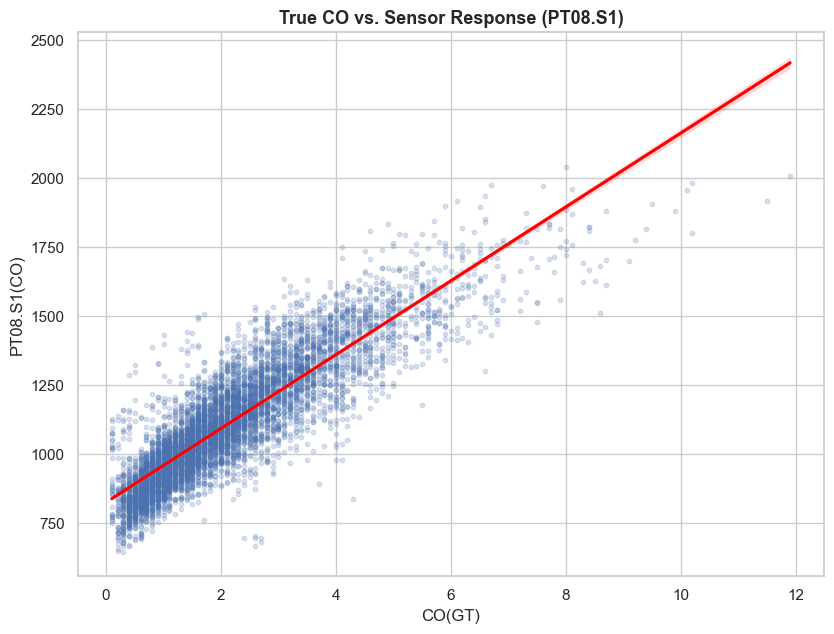

In [74]:
fig, ax = plt.subplots(figsize=(8.5,6.5))
sns.regplot(data=df, x='CO(GT)', y='PT08.S1(CO)', ax=ax,
            scatter_kws={'alpha':0.2, 's':10}, line_kws={'color':'red'})
ax.set_title("True CO vs. Sensor Response (PT08.S1)", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()



<div dir="rtl">
تفسیر نمودار: رابطه‌ی بین `CO(GT)` و `PT08.S1(CO)` به‌طور کلی خطی و مثبت است و خط رگرسیون به‌خوبی روند داده را دنبال می‌کند. اما با دقت بیشتر، پراکندگی عمودی نقاط در هر مقدار مشخص از CO(GT) قابل‌توجه است — مثلاً وقتی CO(GT) برابر ۴ است، پاسخ سنسور می‌تواند از حدود ۱۱۰۰ تا ۱۷۰۰ متغیر باشد. این پراکندگی نشان می‌دهد یک مدل کالیبراسیون ساده‌ی خطی به‌تنهایی برای تبدیل دقیق پاسخ سنسور به غلظت واقعی کافی نیست و عوامل دیگری (مثل دما، رطوبت یا حساسیت متقاطع با گازهای دیگر) هم روی پاسخ سنسور اثر می‌گذارند.
</div>

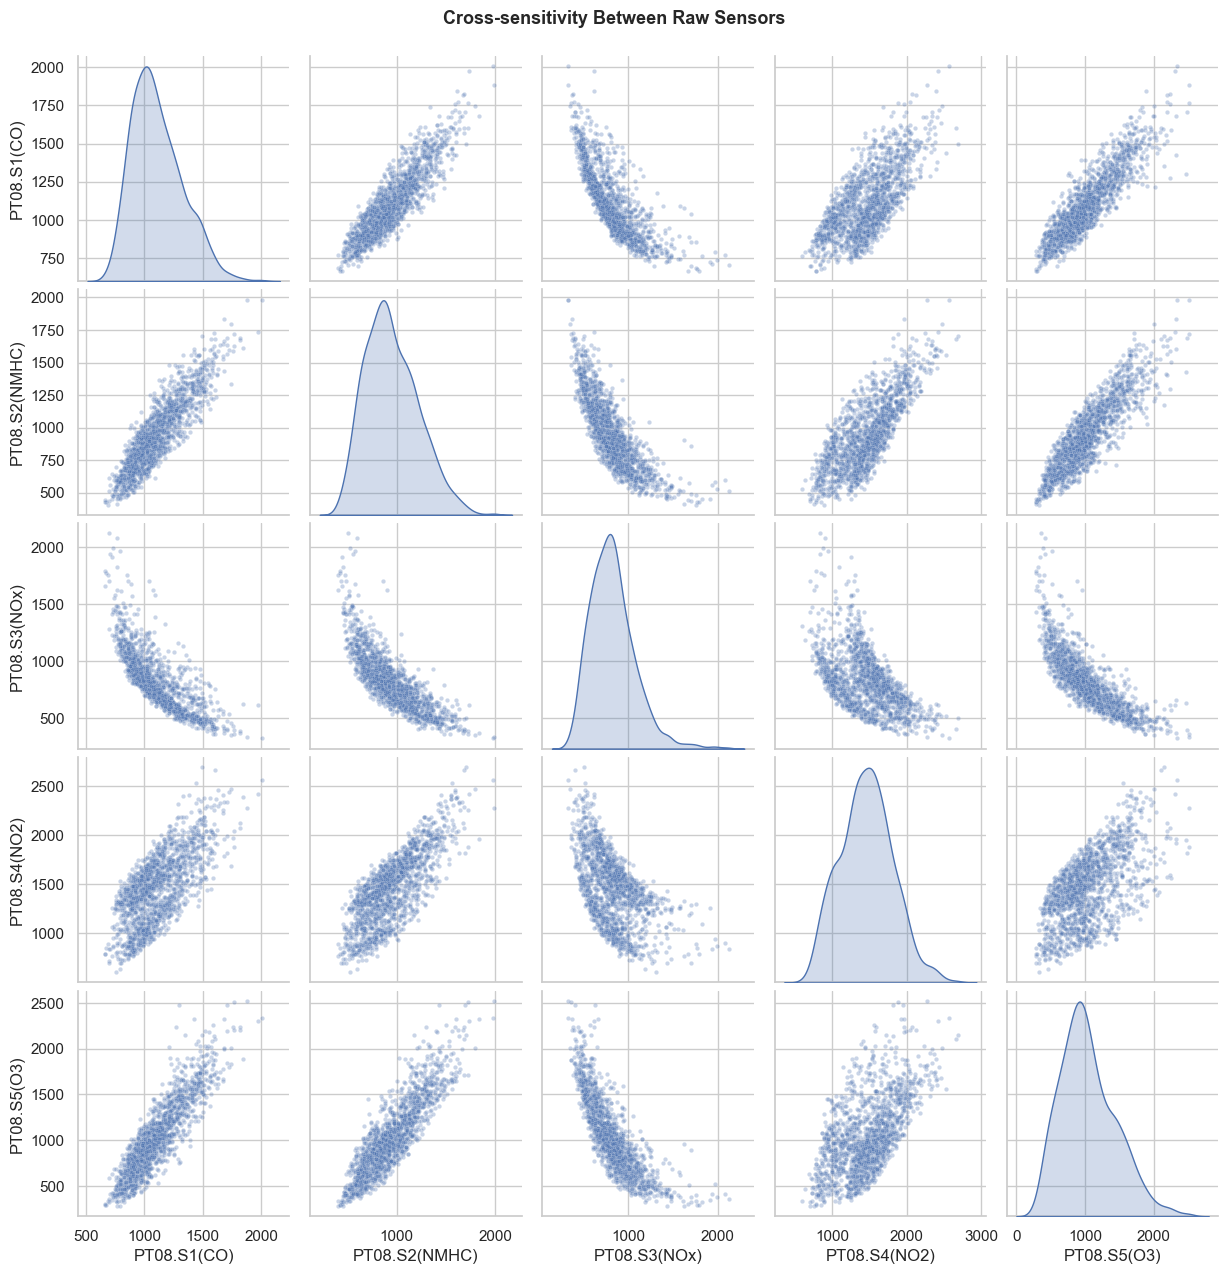

In [75]:
pt08_cols = ['PT08.S1(CO)','PT08.S2(NMHC)','PT08.S3(NOx)','PT08.S4(NO2)','PT08.S5(O3)']
sns.pairplot(df[pt08_cols].dropna().sample(1500, random_state=42), diag_kind='kde',
             plot_kws={'alpha':0.3, 's':10})
plt.suptitle("Cross-sensitivity Between Raw Sensors", y=1.02, fontsize=13, weight='bold')
plt.show()

<div dir="rtl">
تفسیر نمودار: این ماتریس پراکندگی، یافته‌ی بخش قبل را به‌شکل بصری تأیید می‌کند. تمام سنسورها (`PT08.S1`, `S2`, `S4`, `S5`) با یکدیگر رابطه‌ی مثبت و تقریباً خطی دارند — منطقی است چون همه به آلاینده‌های حاصل از احتراق واکنش نشان می‌دهند. اما هر نموداری که شامل `PT08.S3(NOx)` است، یک الگوی کاملاً معکوس و غیرخطی (شبیه هذلولی) نشان می‌دهد. این تصویر به‌روشنی ثابت می‌کند که رفتار این سنسور خاص با بقیه متفاوت است و برای استفاده از آن، باید یک مدل کالیبراسیون جداگانه (و احتمالاً غیرخطی) طراحی کرد.
</div>

## بخش هشتم: آیا سنسورها با گذشت زمان دقتشان را از دست می‌دهند؟ (Sensor Drift)

C:\Users\asus\AppData\Local\Temp\ipykernel_19812\510500854.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_by_month = df.groupby('yearmonth').apply(


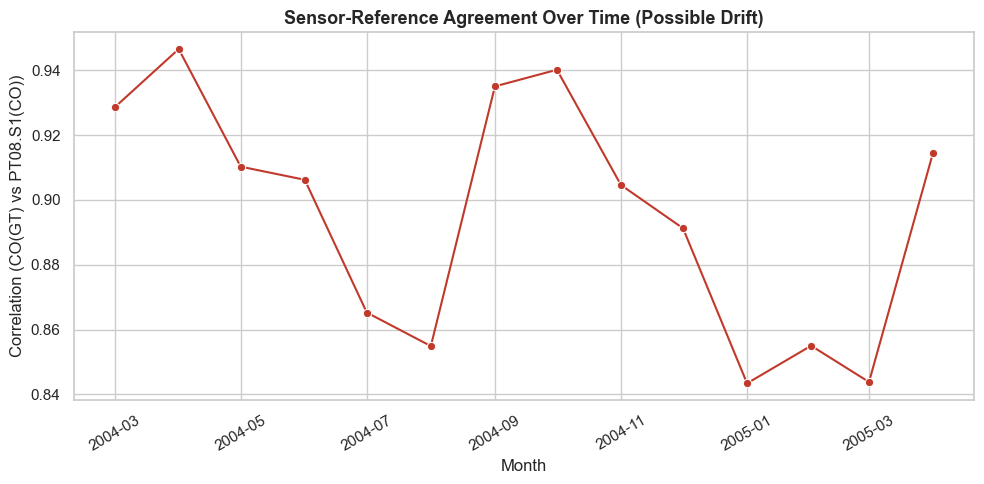

In [76]:
df['yearmonth'] = df['datetime'].dt.to_period('M')
corr_by_month = df.groupby('yearmonth').apply(
    lambda g: g['CO(GT)'].corr(g['PT08.S1(CO)'])
).reset_index()
corr_by_month.columns = ['yearmonth', 'correlation']
corr_by_month['date'] = corr_by_month['yearmonth'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(10,5))
sns.lineplot(data=corr_by_month, x='date', y='correlation', marker='o', ax=ax, color='#c0392b')
ax.set_title("Sensor-Reference Agreement Over Time (Possible Drift)", fontsize=13, weight='bold')
ax.set_ylabel("Correlation (CO(GT) vs PT08.S1(CO))"); ax.set_xlabel("Month")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: همبستگی ماهانه‌ی `CO(GT)` و `PT08.S1(CO)` ثابت نیست و نوسان محسوسی دارد؛ از حدود ۰.۹۵ در آوریل ۲۰۰۴ به پایین‌ترین مقدار ۰.۸۴ در ژانویه و مارس ۲۰۰۵ کاهش می‌یابد و در پایان دوره (آوریل ۲۰۰۵) دوباره کمی بهبود پیدا می‌کند. این افت و نوسان، هرچند شدید نیست، اما با ادعای مقاله‌ی اصلی دیتاست مبنی بر وجود drift مفهومی و حسی در طول یک سال همخوانی دارد. نتیجه‌ی عملی این است که یک مدل کالیبراسیون که در بهار آموزش داده شود، ممکن است در زمستان همان دقت را نداشته باشد و برای کاربرد واقعی، سنسور نیاز به کالیبراسیون دوره‌ای دارد.
</div>

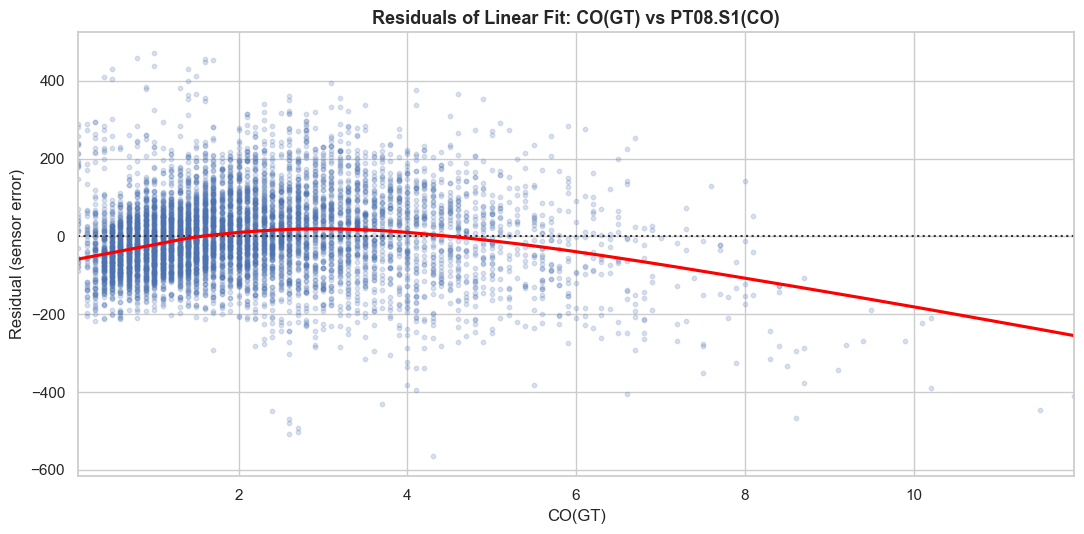

In [77]:
sub = df.dropna(subset=['CO(GT)','PT08.S1(CO)'])

fig, ax = plt.subplots(figsize=(11,5.5))
sns.residplot(data=sub, x='CO(GT)', y='PT08.S1(CO)', lowess=True, ax=ax,
              scatter_kws={'alpha':0.2, 's':10}, line_kws={'color':'red'})
ax.set_title("Residuals of Linear Fit: CO(GT) vs PT08.S1(CO)", fontsize=13, weight='bold')
ax.set_xlabel("CO(GT)"); ax.set_ylabel("Residual (sensor error)")
plt.tight_layout()
plt.show()

<div dir="rtl">
تفسیر نمودار: اگر رابطه‌ی سنسور و مقدار مرجع کاملاً خطی بود، انتظار داشتیم نقاط باقیمانده (residuals) به‌طور تصادفی و بدون الگو حول خط صفر پخش شوند. اما خط لوس (lowess) یک انحنای ملایم نشان می‌دهد: در مقادیر پایین CO(GT) باقیمانده‌ها کمی مثبت هستند، حوالی CO=۲ تا ۳ به صفر نزدیک می‌شوند و در مقادیر بالای CO(GT) (بالای ۶) به‌طور پیوسته منفی و رو به کاهش می‌شوند. این الگو نشان می‌دهد سنسور در غلظت‌های بالا دچار اشباع (Saturation) می‌شود و مقدار واقعی را دست‌کم برآورد می‌کند — یک محدودیت مهم که باید در کاربردهای عملی این سنسور در نظر گرفته شود.
</div>

## بخش نهم: مقایسه‌ی آلاینده‌ها با یکدیگر

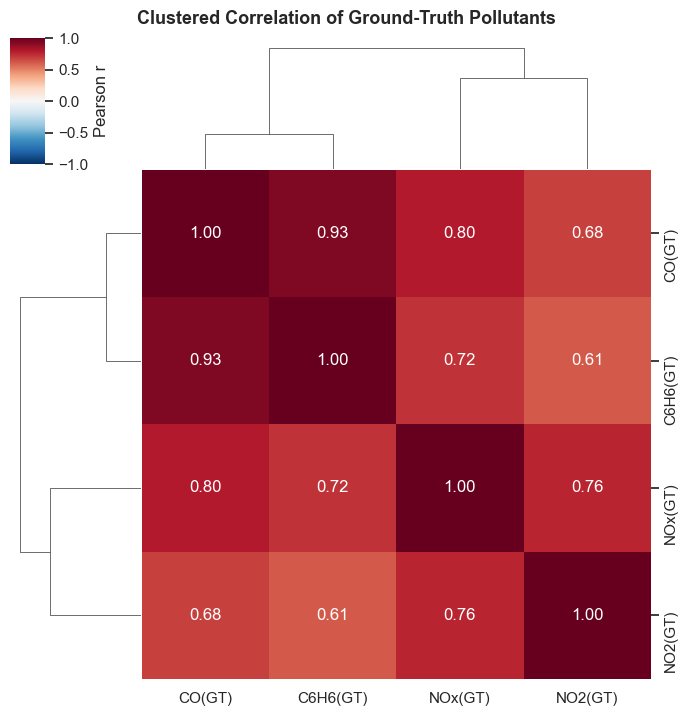

In [78]:
gt_cols = ['CO(GT)','C6H6(GT)','NOx(GT)','NO2(GT)']
corr_gt = df[gt_cols].corr()

g = sns.clustermap(corr_gt, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                    figsize=(7,7), cbar_kws={'label':'Pearson r'})
g.fig.suptitle("Clustered Correlation of Ground-Truth Pollutants", y=1.02, fontsize=13, weight='bold')
plt.show()

<div dir="rtl">
تفسیر نمودار: دندروگرام (نمودار درختی) بالای نقشه نشان می‌دهد `CO(GT)` و `C6H6(GT)` (بنزن) اولین جفتی هستند که در یک خوشه قرار می‌گیرند (همبستگی ۰.۹۳) — این دو منطقی است چون هر دو مستقیماً از احتراق ناقص سوخت وسایل نقلیه منتشر می‌شوند و تقریباً منشأ مشترک دارند. `NOx(GT)` و `NO2(GT)` هم جفت دوم را تشکیل می‌دهند (همبستگی ۰.۷۶)، اما با همبستگی کمی پایین‌تر با جفت اول (بین ۰.۶۱ تا ۰.۸۰). این خوشه‌بندی نشان می‌دهد اگرچه همه‌ی آلاینده‌ها ریشه‌ی ترافیکی مشترک دارند، اما دو زیرگروه شیمیایی نسبتاً متمایز (هیدروکربن‌ها در برابر اکسیدهای نیتروژن) در داده وجود دارد.
</div>

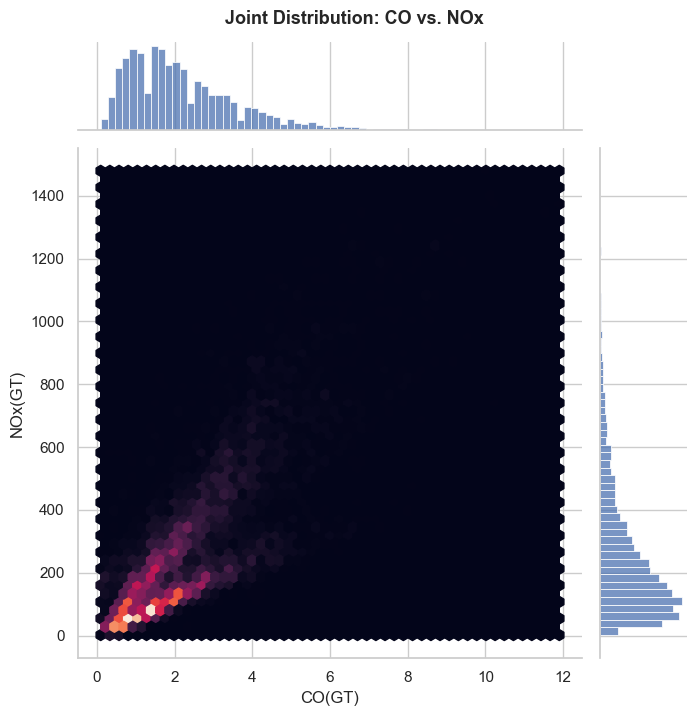

In [79]:
sub = df.dropna(subset=['CO(GT)','NOx(GT)'])
g = sns.jointplot(data=sub, x='CO(GT)', y='NOx(GT)', kind='hex', cmap='rocket', height=7)
g.fig.suptitle("Joint Distribution: CO vs. NOx", fontsize=13, weight='bold', y=1.02)
plt.show()

<div dir="rtl">
تفسیر نمودار: توزیع توأم CO و NOx یک رابطه‌ی مثبت و تقریباً خطی در مقادیر پایین (که اکثریت داده در آنجا متمرکز است) نشان می‌دهد — ناحیه‌ی روشن‌ترِ گوشه‌ی پایین-چپ نمودار، متراکم‌ترین نقاط داده را دربردارد. با افزایش CO، NOx هم افزایش می‌یابد، اما با پراکندگی بیشتر (چند نقطه با CO پایین ولی NOx بسیار بالا هم دیده می‌شود)، که نشان می‌دهد این دو آلاینده هرچند منشأ مشترک دارند، کاملاً یکسان رفتار نمی‌کنند. نکته‌ی فنی: چون تعداد بسیار زیادی از بین (bin)های شش‌ضلعی بدون داده هستند، نرم‌افزار آن‌ها را با تیره‌ترین رنگ نقشه‌ی رنگی (rocket) پر کرده که پس‌زمینه‌ی نمودار را تیره نشان می‌دهد؛ توجه اصلی باید به نواحی روشن (پرتراکم) در گوشه‌ی پایین سمت چپ باشد.
</div>

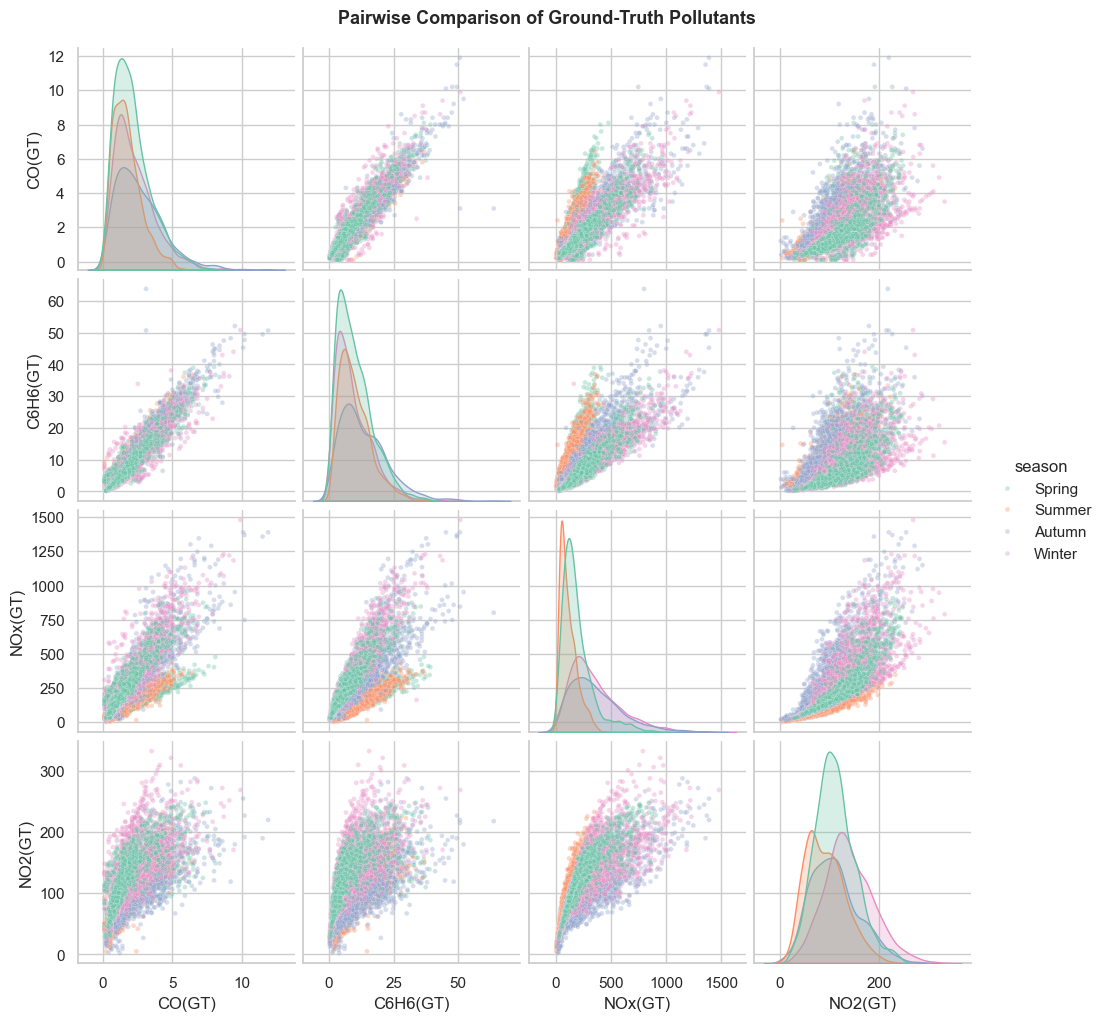

In [80]:
gt_cols_ext = ['CO(GT)','C6H6(GT)','NOx(GT)','NO2(GT)']
sns.pairplot(df[gt_cols_ext + ['season']].dropna(), hue='season', hue_order=order,
             palette='Set2', plot_kws={'alpha':0.35, 's':12}, diag_kind='kde')
plt.suptitle("Pairwise Comparison of Ground-Truth Pollutants", y=1.02, fontsize=13, weight='bold')
plt.show()

<div dir="rtl">
تفسیر نمودار: این نمودار جامع، بسیاری از یافته‌های قبلی را در یک نگاه خلاصه می‌کند. تمام جفت‌های آلاینده رابطه‌ی مثبت نشان می‌دهند، اما با شدت‌های متفاوت (CO-Benzene قوی‌تر از NOx-NO2). نکته‌ی جالب‌تر رنگ‌بندی بر اساس فصل است: نقاط تابستان (نارنجی) به‌وضوح در ناحیه‌ی مقادیر پایین هر دو محور خوشه شده‌اند (کمترین آلودگی)، درحالی‌که نقاط زمستان (صورتی) در نمودارهای مربوط به NOx و NO2 اغلب دورترین و بالاترین مقادیر را نشان می‌دهند. نمودارهای قطری (توزیع تک‌متغیره) هم تأیید می‌کنند که توزیع تابستان (نارنجی) نسبت به بقیه‌ی فصل‌ها باریک‌تر و به سمت مقادیر پایین‌تر متمایل است — دقیقاً همان الگوی فصلی که در ابتدای تحلیل دیدیم.
</div>

## جمع‌بندی نهایی

با کنار هم گذاشتن تمام نمودارها، داستان کامل این‌گونه روایت می‌شود:

1. **کیفیت داده در وهله‌ی اول اهمیت دارد** — بدون شناسایی و جایگزینی مقدار -200، هیچ‌کدام از آمار توصیفی و نمودارهای بعدی معتبر نبودند؛ ستون `NMHC(GT)` هم به‌دلیل ۹۰٪ مقدار گمشده عملاً غیرقابل‌استفاده است.
2. **این داده‌ها بازتاب مستقیم زندگی شهری هستند:** الگوی روزانه (دو قله‌ی ترافیک صبح/عصر) و الگوی هفتگی (روز کاری در برابر آخر هفته) هر دو به‌وضوح در غلظت آلاینده‌ها دیده می‌شوند — منبع اصلی آلودگی، ترافیک خودرو است.
3. **فصل و دما تأثیرگذارند، اما رابطه ساده نیست:** به‌طور کلی هوای سرد و مرطوب معتدل آلوده‌تر است (به‌دلیل وارونگی دمایی)، اما تعطیلات تابستانی، توزیع فصلی بنزن، و رفتار متفاوت NO2 نشان می‌دهند این رابطه چندبعدی است.
4. **سنسورهای ارزان‌قیمت مفیدند ولی بی‌نقص نیستند:** اکثر آن‌ها همبستگی خوبی با مقدار مرجع دارند، اما پدیده‌ی حساسیت متقاطع (رفتار معکوس `PT08.S3(NOx)`)، اشباع در غلظت‌های بالا، و افت تدریجی دقت در طول زمان (drift) نشان می‌دهد این سنسورها برای استفاده‌ی دقیق در دنیای واقعی به **کالیبراسیون دوره‌ای و مدل‌های تصحیح غیرخطی** نیاز دارند.

این دو داستان — شهر و ابزار اندازه‌گیری آن — در نهایت یک نتیجه‌ی مشترک دارند: داده‌های محیطی، حتی وقتی از حسگرهای ساده به‌دست می‌آیند، می‌توانند الگوهای انسانی و فنی پیچیده‌ای را آشکار کنند، به‌شرط آنکه با دقت پاکسازی و تفسیر شوند.
